In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
from PIL import Image
from torch.utils.data import TensorDataset, DataLoader
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import normalize
from scipy.sparse import hstack, csr_matrix

In [2]:
test_df = pd.read_csv("test_split.csv").fillna("")

In [3]:
tfv = joblib.load("tfidf.pkl")
text_model = joblib.load("text_model.pkl")

In [4]:
X_test_text = test_df["title"] + " " + test_df["description"]
X_test_tfv = tfv.transform(X_test_text)

In [5]:
text_proba = text_model.predict_proba(X_test_tfv)
text_proba.shape

(8400, 21)

In [6]:
test_images = []
for p in test_df["path"]:
      img = np.array(Image.open(p).convert("RGB"))
      test_images.append(img)

X_test_img = np.stack(test_images)  
X_test_img = torch.tensor(X_test_img).permute(0, 3, 1, 2)    
X_test_img.shape

torch.Size([8400, 3, 100, 100])

In [7]:
test_load = DataLoader(TensorDataset(X_test_img), batch_size=64)

In [8]:
device = "cuda"
model = models.resnet18()
model.fc = nn.Linear(512, 21)
model.load_state_dict(torch.load("resnet.pt"))
model = model.to(device)
model.eval()
mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(device)
std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(device)

In [9]:
probs = []

with torch.no_grad():
    for batch in test_load:
        x = batch[0].to(device).float() / 255
        x = F.interpolate(x, size=224)
        x = (x - mean) / std
        out = model(x)
        probs.append(F.softmax(out, dim=1).cpu())

image_proba = torch.cat(probs).numpy()
image_proba.shape

(8400, 21)

## Мультимодальна модель: склеюємо ознаки тексту (TF-IDF) і фото (ResNet) та вчимо одну логістичну регресію

In [10]:
train_df = pd.read_csv("train_split.csv").fillna("")
X_train_tfv = tfv.transform(train_df["title"] + " " + train_df["description"])

In [11]:
train_images = []
for p in train_df["path"]:
      img = np.array(Image.open(p).convert("RGB"))
      train_images.append(img)

X_train_img = np.stack(train_images)
X_train_img = torch.tensor(X_train_img).permute(0, 3, 1, 2)
del train_images

train_load = DataLoader(TensorDataset(X_train_img), batch_size=64)
X_train_img.shape

torch.Size([33600, 3, 100, 100])

In [12]:
fe = models.resnet18(weights="DEFAULT")
fe.fc = nn.Identity()
fe = fe.to(device)
fe.eval();

In [13]:
def get_features(loader):
    feats = []
    with torch.no_grad():
        for batch in loader:
            x = batch[0].to(device).float() / 255
            x = F.interpolate(x, size=224)
            x = (x - mean) / std
            feats.append(fe(x).cpu())
    return torch.cat(feats).numpy()

train_feat = get_features(train_load)
test_feat = get_features(test_load)
train_feat.shape, test_feat.shape

((33600, 512), (8400, 512))

In [14]:
train_feat = normalize(train_feat)
test_feat = normalize(test_feat)

X_train_multi = hstack([X_train_tfv, csr_matrix(train_feat)])
X_test_multi = hstack([X_test_tfv, csr_matrix(test_feat)])
X_train_multi.shape

(33600, 50512)

In [15]:
multi_model = LogisticRegression(max_iter=1000)
multi_model.fit(X_train_multi, train_df["categories"]);

In [16]:
early_pred = multi_model.predict(X_test_multi)
print(classification_report(test_df["categories"], early_pred))

                           precision    recall  f1-score   support

               All Beauty       0.73      0.69      0.71       400
          All Electronics       0.66      0.59      0.62       400
               Appliances       0.93      0.91      0.92       400
    Arts, Crafts & Sewing       0.79      0.84      0.82       400
               Automotive       0.85      0.84      0.84       400
                     Baby       0.71      0.80      0.75       400
            Baby Products       0.79      0.62      0.70       400
                   Beauty       0.75      0.71      0.73       400
Cell Phones & Accessories       0.86      0.90      0.88       400
Clothing, Shoes & Jewelry       0.76      0.81      0.78       400
              Electronics       0.82      0.84      0.83       400
   Grocery & Gourmet Food       0.88      0.94      0.91       400
   Health & Personal Care       0.72      0.70      0.71       400
  Industrial & Scientific       0.72      0.74      0.73     

In [17]:
text_pred = text_model.classes_[text_proba.argmax(1)]
image_pred = text_model.classes_[image_proba.argmax(1)]
true = test_df["categories"].values

In [18]:
text_wrong_image_right = (text_pred != true) & (image_pred == true)
image_wrong_text_right = (image_pred != true) & (text_pred == true)

print(text_wrong_image_right.sum(), image_wrong_text_right.sum())

337 3025


Micro Innovations KP17B Numeric Keypad
правильно: Electronics | текст: All Electronics | фото: Electronics


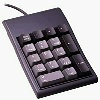

Behringer MX882 8-Channel Splitter/Mixer
правильно: Musical Instruments | текст: All Electronics | фото: Musical Instruments


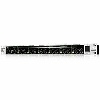

Falcon Safety Super Sound Horn
правильно: Sports & Outdoors | текст: Musical Instruments | фото: Sports & Outdoors


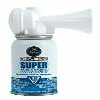

L'Oreal Dermo-Expertise RevitaLift Eye Cream 15ml/0.5oz
правильно: Beauty | текст: All Beauty | фото: Beauty


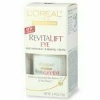

PREMIUM USB Adapter Power Kit for your HTC HD2 Phone! Includes : (1) A Days Tech Charging USB Data Cable, (1) USB Car Charger Adapter (1) USB Folding Blade Wall Charger Adapter.
правильно: Electronics | текст: Cell Phones & Accessories | фото: Electronics


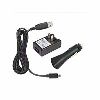

In [19]:
idx = np.where(text_wrong_image_right)[0][:5]

for i in idx:
    print(test_df["title"].iloc[i])
    print("правильно:", true[i], "| текст:", text_pred[i], "| фото:", image_pred[i])
    display(Image.open(test_df["path"].iloc[i]))

# Текст помилився, а фото вгадало

| товар | правильно | текст | чому |
|---|---|---|---|
| Numeric Keypad | Electronics | All Electronics | схожі категорії, фото вгадало випадково |
| Behringer 8-Channel Mixer | Musical Instruments | All Electronics | у тексті технічні слова, а на фото видно мікшерний пульт |
| Falcon Sound Horn | Sports & Outdoors | Musical Instruments | текст обдурило слово "Sound", а на фото балончик-сирена |
| L'Oreal Eye Cream | Beauty | All Beauty | схожі категорії, фото вгадало випадково |
| USB Adapter для HTC | Electronics | Cell Phones & Accessories | у тексті "Phone" і "HTC", спірний випадок |


Victor M130 Quick Set! Mouse Trap
правильно: Patio, Lawn & Garden | текст: Patio, Lawn & Garden | фото: All Electronics


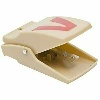

GPX AHP3700RS Rugged Sports Digital Tune AM/FM Stereo Headphone Radio
правильно: Electronics | текст: Electronics | фото: Cell Phones & Accessories


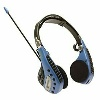

Westinghouse 66201 Semi-Flush Mount Square Ceiling Fixture
правильно: Tools & Home Improvement | текст: Tools & Home Improvement | фото: Appliances


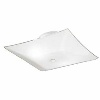

Golden Acrylic Flow Release - 8 oz Bottle
правильно: Arts, Crafts & Sewing | текст: Arts, Crafts & Sewing | фото: Beauty


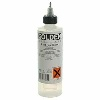

Motorola Slim Battery
правильно: Cell Phones & Accessories | текст: Cell Phones & Accessories | фото: Musical Instruments


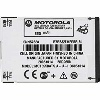

In [20]:
idx = np.where(image_wrong_text_right)[0][:5]

for i in idx:
    print(test_df["title"].iloc[i])
    print("правильно:", true[i], "| текст:", text_pred[i], "| фото:", image_pred[i])
    display(Image.open(test_df["path"].iloc[i]))

### Фото помилилось, а текст вгадав

| товар | правильно | фото | чому |
|---|---|---|---|
| Victor Mouse Trap | Patio, Lawn & Garden | All Electronics | на фото пластикова коробочка, схожа на гаджет |
| GPX Headphone Radio | Electronics | Cell Phones & Accessories | на фото навушники, їх часто продають як аксесуари до телефонів |
| Westinghouse Ceiling Fixture | Tools & Home Improvement | Appliances | світильник схожий на побутовий прилад |
| Golden Acrylic Flow Release | Arts, Crafts & Sewing | Beauty | пляшечка з дозатором схожа на лосьйон |
| Motorola Slim Battery | Cell Phones & Accessories | Musical Instruments | маленький прямокутник, написи на фото 100×100 не прочитати |

Фото допомагає, коли текст вводить в оману окреме слово. Але набагато частіше фото помиляється там, де текст правий, бо різні товари схоже виглядають.


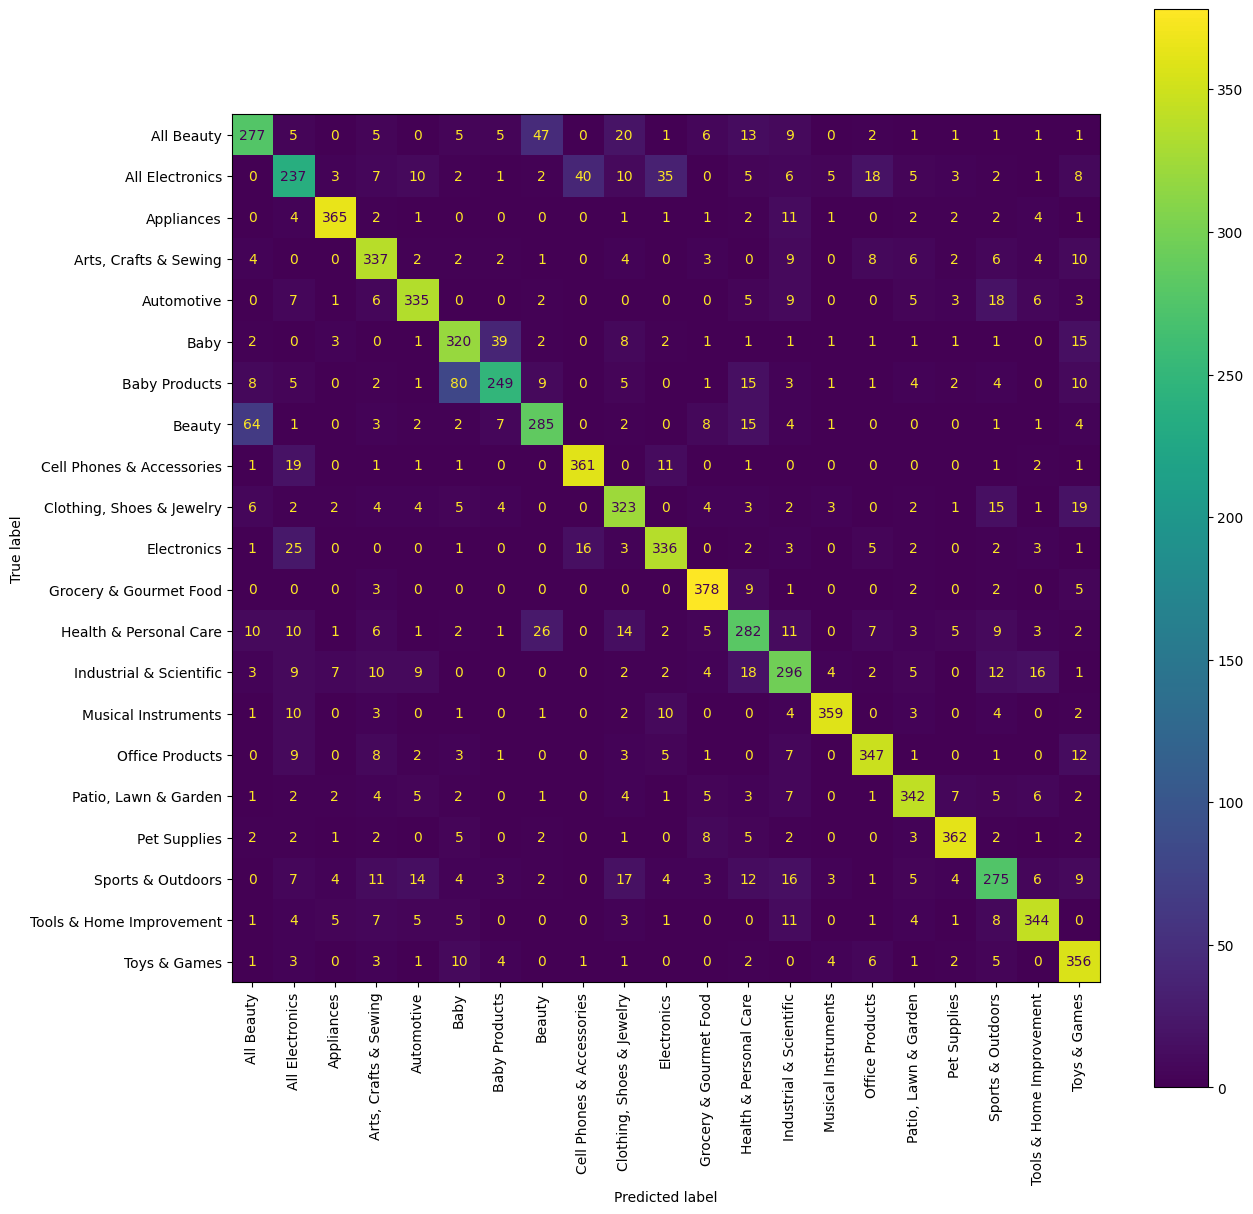

In [21]:
fig, ax = plt.subplots(figsize=(14, 14))
ConfusionMatrixDisplay.from_predictions(test_df["categories"], early_pred, ax=ax, xticks_rotation="vertical")
plt.show()

## Висновки

| модель | accuracy | F1 |
|---|---|---|
| текст | 0.82 | 0.82 |
| фото (моя CNN) | 0.30 | 0.29 |
| фото (ResNet18) | 0.50 | 0.50 |
| текст + фото | 0.81 | 0.80 |

- Текст працює найкраще, бо в назві часто прямо написано, що це за товар.
- Фото слабші: вони маленькі, і різні товари часто виглядають однаково.
- Разом з фото результат майже не змінився: фото виправило текст лише 337 разів, а помилилось 3025 разів там, де текст був правий.
- Найбільше помилок у всіх моделей між схожими категоріями (Beauty / All Beauty, Baby / Baby Products, Electronics / All Electronics). Їх не розрізняє ні текст, ні фото.
